# Multi‑Year Analysis of Austria’s Electricity Demand and Renewables

The dataset used in this project is the Open Power System Data time‑series package for Austria (2015–mid‑2020). It contains hourly time‑series for several variables relevant to power‑system analysis, including total electricity load (consumption), day‑ahead market prices, and actual solar and onshore wind generation, all aggregated at the country level. The data is compiled from ENTSO‑E Transparency sources.

Link: https://data.open-power-system-data.org/time_series 

## Motivation
Understanding how electricity demand and renewable generation behave over time is essential for planning and operating a secure, low‑carbon power system. By analysing Austria’s multi‑year load, price, solar, and wind time‑series, this project aims to identify typical patterns such as daily and seasonal variation, weekday–weekend effects, and the relationship between demand and market prices. These insights are directly relevant for topics like integrating more wind and solar power, designing flexible demand, and assessing future system needs in the context of the European energy transition.

![Smart grid with renewable energy sources.](stock-vector-smart-grid-as-electricity-power-flow-management-and-control-outline-diagram-labeled-educational-2177496773.jpg)



In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sn


df_austria = pd.read_csv('timeseries_60min_Austria.csv')
df_austria

,utc_timestamp,cet_cest_timestamp,AT_load_actual_entsoe_transparency,AT_load_forecast_entsoe_transparency,AT_price_day_ahead,AT_solar_generation_actual,AT_wind_onshore_generation_actual
0,2014-12-31T23:00:00Z,2015-01-01T00:00:00+0100,NaN,NaN,NaN,NaN,NaN
1,2015-01-01T00:00:00Z,2015-01-01T01:00:00+0100,5946.0,6701.0,35.0,NaN,69.0
2,2015-01-01T01:00:00Z,2015-01-01T02:00:00+0100,5726.0,6593.0,45.0,NaN,64.0
3,2015-01-01T02:00:00Z,2015-01-01T03:00:00+0100,5347.0,6482.0,41.0,NaN,65.0
4,2015-01-01T03:00:00Z,2015-01-01T04:00:00+0100,5249.0,6454.0,38.0,NaN,64.0
...,...,...,...,...,...,...,...
50396,2020-09-30T19:00:00Z,2020-09-30T21:00:00+0200,6661.0,6656.0,NaN,NaN,1847.0
50397,2020-09-30T20:00:00Z,2020-09-30T22:00:00+0200,6336.0,6310.0,NaN,NaN,1723.0
50398,2020-09-30T21:00:00Z,2020-09-30T23:00:00+0200,5932.0,5813.0,NaN,NaN,1771.0
50399,2020-09-30T22:00:00Z,2020-10-01T00:00:00+0200,5628.0,5424.0,NaN,NaN,1779.0


In [3]:
df_austria.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50401 entries, 0 to 50400
Data columns (total 7 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   utc_timestamp                         50401 non-null  object 
 1   cet_cest_timestamp                    50401 non-null  object 
 2   AT_load_actual_entsoe_transparency    50400 non-null  float64
 3   AT_load_forecast_entsoe_transparency  50400 non-null  float64
 4   AT_price_day_ahead                    32845 non-null  float64
 5   AT_solar_generation_actual            50339 non-null  float64
 6   AT_wind_onshore_generation_actual     50352 non-null  float64
dtypes: float64(5), object(2)
memory usage: 2.7+ MB


In [4]:
#removing the NaN values
df_filtered = df_austria.dropna()

print('After removing the NaN values: ', df_filtered.shape)

After removing the NaN values:  (32790, 7)


In [5]:
df_filtered["cet_cest_timestamp"] = pd.to_datetime(df_filtered["cet_cest_timestamp"], utc=True)

df = df_filtered.sort_values("cet_cest_timestamp")
df = df.set_index("cet_cest_timestamp")

df["year"] = df.index.year
df["month"] = df.index.month
df["hour"] = df.index.hour
df["weekday"] = df.index.weekday
df["dayofyear"] = df.index.dayofyear  # 0=Mon,...,6=Sun


C:\Users\aditi\AppData\Local\Temp\ipykernel_108096\2515640954.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered["cet_cest_timestamp"] = pd.to_datetime(df_filtered["cet_cest_timestamp"], utc=True)


### Multi‑year load trend
This plot shows the evolution of Austria’s average and/or peak hourly load from 2015 to 2020. Over multiple years, the trend illustrates whether electricity demand is increasing, decreasing, or relatively stable, which is important for long‑term system planning.
The yearly peak values are noticeably higher than the yearly averages, illustrating the need to size the system for rare but high‑demand hours.

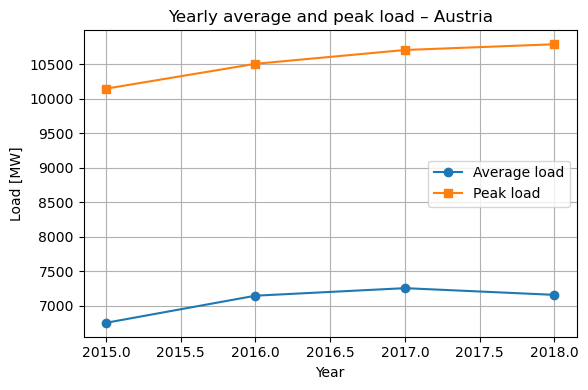

In [6]:
load_col = "AT_load_actual_entsoe_transparency"  

yearly_avg = df.groupby("year")[load_col].mean()
yearly_peak = df.groupby("year")[load_col].max()

plt.figure(figsize=(6, 4))
plt.plot(yearly_avg.index, yearly_avg.values, marker="o", label="Average load")
plt.plot(yearly_peak.index, yearly_peak.values, marker="s", label="Peak load")
plt.xlabel("Year")
plt.ylabel("Load [MW]")
plt.title("Yearly average and peak load – Austria")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


### Monthly Average Load

The average monthly load profile aggregated over the full 2015–2020 period reveals a clear seasonal pattern. Higher loads occur in winter months, while summer months show lower demand, reflecting the influence of heating, lighting, and seasonal industrial activity on electricity use. 

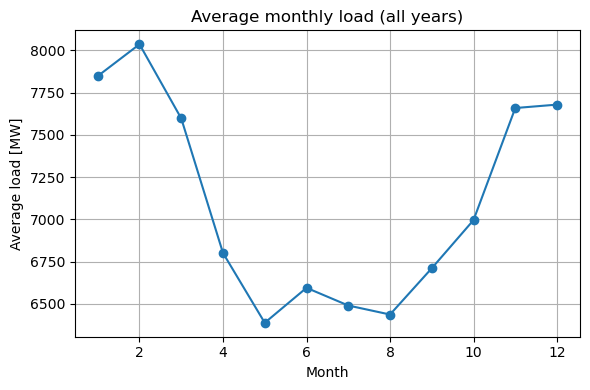

In [7]:
monthly_avg = df.groupby("month")[load_col].mean()

plt.figure(figsize=(6, 4))
plt.plot(monthly_avg.index, monthly_avg.values, marker="o")
plt.xlabel("Month")
plt.ylabel("Average load [MW]")
plt.title("Average monthly load (all years)")
plt.grid(True)
plt.tight_layout()
plt.show()


### Average daily profile (all years)

Plot: A curve with 24 points (hours 0–23) showing average load at each hour of day, averaged over the entire dataset.

The average daily load profile shows a typical intraday pattern with low demand during the night, a rise in the morning, and a pronounced evening peak. This shape reflects human activity: residential and commercial consumption increases when people wake up, work, and return home, then decreases again late at night.

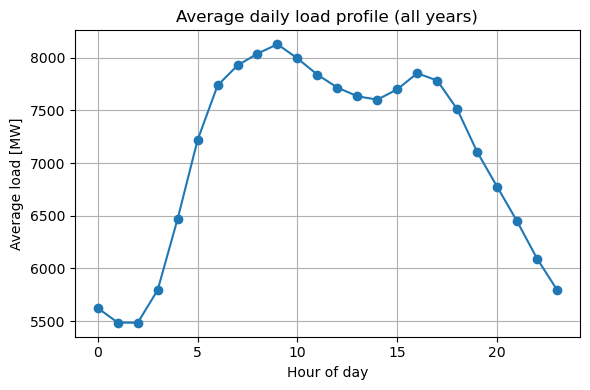

In [8]:
avg_by_hour_all = df.groupby("hour")[load_col].mean()


plt.figure(figsize=(6, 4))
plt.plot(avg_by_hour_all.index, avg_by_hour_all.values, marker="o")
plt.xlabel("Hour of day")
plt.ylabel("Average load [MW]")
plt.title("Average daily load profile (all years)")
plt.grid(True)
plt.tight_layout()
plt.show()


### Average load by weekday (all years)

Plot: A bar chart with seven bars labelled 0–6 (Monday–Sunday) showing mean load for each weekday.

The average load by weekday indicates that electricity demand is generally higher on weekdays than on weekends. This difference reflects the contribution of industrial and commercial consumers, which are typically more active from Monday to Friday and less active on Saturdays and Sundays. The weekday–weekend contrast is a common feature in electricity‑demand time series and is important for scheduling generation and maintenance.

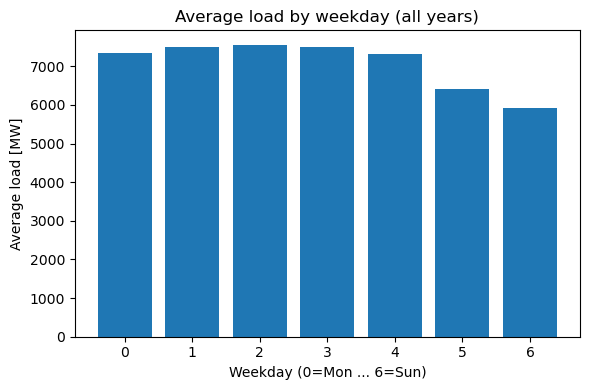

In [9]:
avg_by_weekday_all = df.groupby("weekday")[load_col].mean()

plt.figure(figsize=(6, 4))
plt.bar(avg_by_weekday_all.index, avg_by_weekday_all.values)
plt.xlabel("Weekday (0=Mon ... 6=Sun)")
plt.ylabel("Average load [MW]")
plt.title("Average load by weekday (all years)")
plt.tight_layout()
plt.show()


### Distribution of hourly load

Plot: A histogram where the x‑axis is load in MW and the y‑axis is the number of hours in each bin.

The histogram of hourly load values shows that most hours fall within a central range, while very low and very high loads are comparatively rare. This distribution describes what “normal” operating conditions look like.

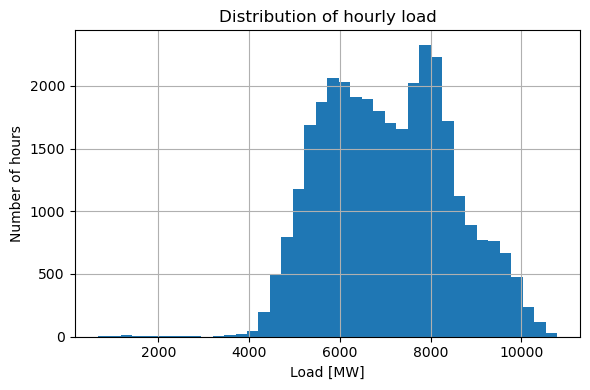

In [10]:
plt.figure(figsize=(6, 4))
df[load_col].hist(bins=40)
plt.xlabel("Load [MW]")
plt.ylabel("Number of hours")
plt.title("Distribution of hourly load")
plt.tight_layout()
plt.show()

###  Price–load scatter 

Plot: A dense cloud of points with load on the x‑axis and day‑ahead price on the y‑axis, spanning the whole 2015–2020 period.

The scatter plot of load versus day‑ahead price illustrates how market prices respond to varying levels of demand. Higher loads are often associated with higher prices, reflecting tighter supply–demand conditions, although the relationship is not perfectly linear due to the influence of fuel prices, renewables, and market design.

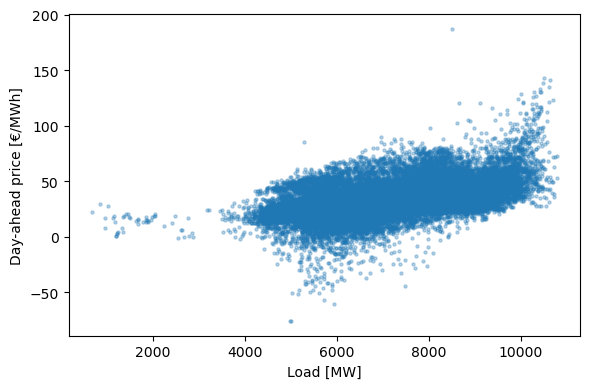

In [11]:
price_col = "AT_price_day_ahead"  
subset = df[[load_col, price_col]].dropna()

plt.figure(figsize=(6, 4))
plt.scatter(subset[load_col], subset[price_col], alpha=0.3, s=5)
plt.xlabel("Load [MW]")
plt.ylabel("Day-ahead price [€/MWh]")
plt.tight_layout()
plt.show()


### Daily-mean load per year

This figure shows the daily mean electricity load for each year in the dataset, with one line per year. The curves confirm a recurring seasonal pattern (higher winter loads, lower summer loads) while also making it easy to visually compare years and identify any differences in overall demand level between them.

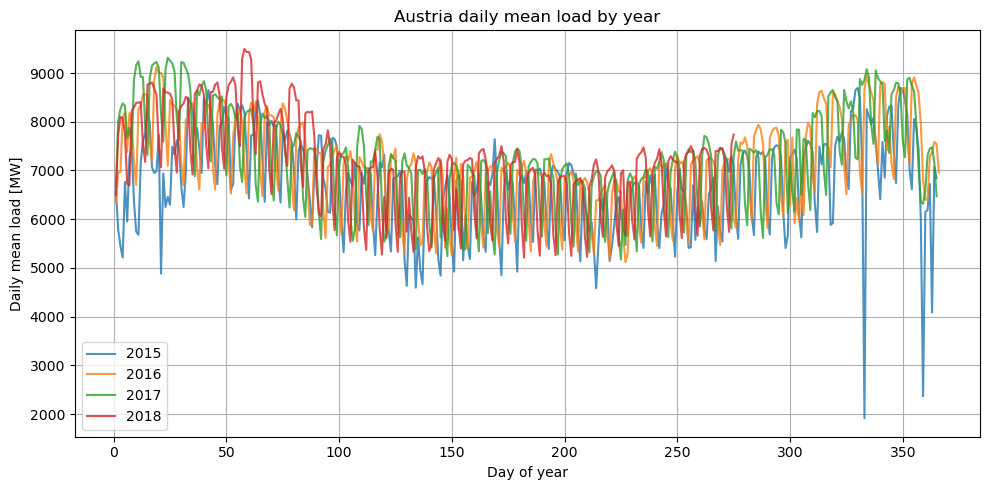

In [12]:
daily = df.groupby(["year", "dayofyear"])[load_col].mean().reset_index()

plt.figure(figsize=(10, 5))

for y in sorted(daily["year"].unique()):
    data_y = daily[daily["year"] == y]
    plt.plot(
        data_y["dayofyear"],
        data_y[load_col],
        label=str(y),
        alpha=0.8
    )

plt.xlabel("Day of year")
plt.ylabel("Daily mean load [MW]")
plt.title("Austria daily mean load by year")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# Conclusion

This project used open time‑series data for Austria (2015–2020) to explore how electricity load, and related variables, vary over time at hourly resolution. The analysis highlighted clear daily and weekly patterns, strong seasonal effects, and multi‑year changes in average demand, demonstrating how typical and extreme operating conditions can be identified using simple visualizations. 
This type of analysis is essential before doing forecasting or system planning studies.

![Thank You](Renewable-Energy-PowerPoint-Theme-Thankyou.jpg)